# 01 · Exploratory analysis — what drives daily grocery sales?

**Data:** [Corporación Favorita](https://www.kaggle.com/competitions/store-sales-time-series-forecasting) (Ecuador) —
daily unit sales for **54 stores × 33 product families**, Jan 2013 – Aug 2017 (3.0M rows), plus store metadata,
promotions, holidays, daily store transactions and oil prices.

All aggregation is done in SQL ([`/sql`](../sql)) with DuckDB. The goal of this notebook is to decide **what the
forecasting model needs to know** — every section ends with a modelling decision.

➡️ Next: [02 · Forecasting](02_forecasting.ipynb)

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

import style
from sql_runner import connect, query

style.apply()
con = connect()

## 1. Data quality first: several families are not recorded for long stretches before mid-2015

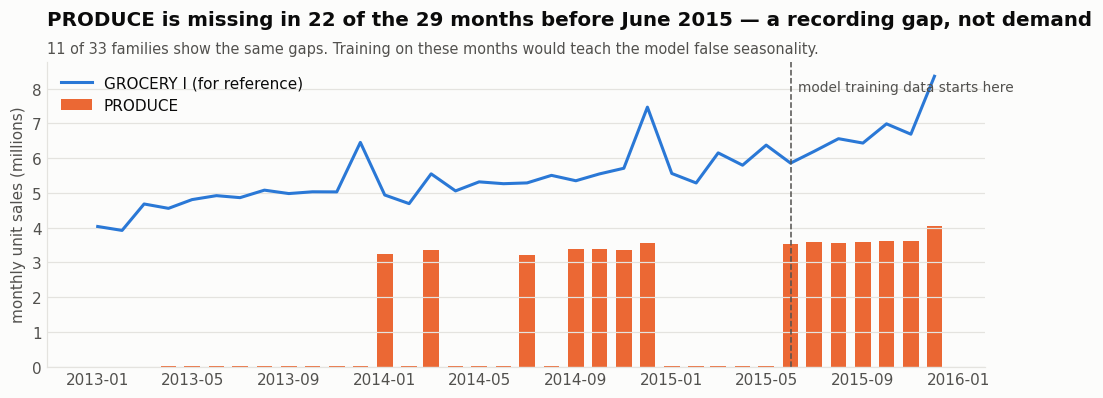

In [2]:
dq = con.execute("""
    SELECT date_trunc('month', date) AS month, family, SUM(sales) AS sales
    FROM sales
    WHERE family IN ('PRODUCE', 'GROCERY I') AND date < DATE '2016-01-01'
    GROUP BY ALL ORDER BY month""").df()
pv = dq.pivot(index="month", columns="family", values="sales") / 1e6

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(pv.index, pv["PRODUCE"], width=20, color=style.ORANGE, label="PRODUCE")
ax.plot(pv.index, pv["GROCERY I"], color=style.BLUE, lw=2, label="GROCERY I (for reference)")
ax.axvline(pd.Timestamp("2015-06-01"), color=style.TEXT_2, lw=1, ls="--")
ax.text(pd.Timestamp("2015-06-10"), pv.values.max() * 0.95, "model training data starts here", color=style.TEXT_2, fontsize=9)
ax.set_ylabel("monthly unit sales (millions)")
ax.legend(loc="upper left")
ax.set_title("PRODUCE is missing in 22 of the 29 months before June 2015 — a recording gap, not demand")
style.subtitle(ax, "11 of 33 families show the same gaps. Training on these months would teach the model false seasonality.")
style.save(fig, "01_data_quality")
plt.show()

**Decision:** train the model on data from **2015-06-01** onwards only. Before that, 11 families have months with
< 20% of their usual volume, switching on and off from one month to the next, which is clearly a data-capture issue.

## 2. Trend and shocks

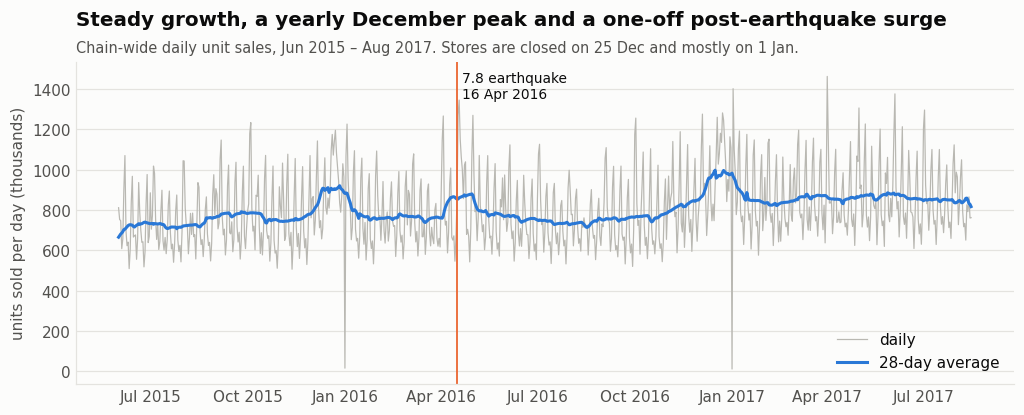

Average daily units, last 12 months vs. previous 12 months: +7.7%


In [3]:
trend = query(con, "01_daily_trend.sql")
trend["date"] = pd.to_datetime(trend.date)
tr = trend[trend.date >= "2015-06-01"]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(tr.date, tr.sales / 1e3, color=style.MUTED, lw=0.8, label="daily")
ax.plot(tr.date, tr.sales_ma28 / 1e3, color=style.BLUE, lw=2, label="28-day average")
quake = pd.Timestamp("2016-04-16")
ax.axvline(quake, color=style.ORANGE, lw=1.2)
ax.text(quake + pd.Timedelta(days=5), ax.get_ylim()[1] * 0.97, "7.8 earthquake\n16 Apr 2016", color=style.TEXT, fontsize=9, va="top")
ax.set_ylabel("units sold per day (thousands)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="lower right")
ax.set_title("Steady growth, a yearly December peak and a one-off post-earthquake surge")
style.subtitle(ax, "Chain-wide daily unit sales, Jun 2015 – Aug 2017. Stores are closed on 25 Dec and mostly on 1 Jan.")
style.save(fig, "02_trend")
plt.show()

last12 = tr[(tr.date > "2016-08-15")].sales.mean()
prev12 = tr[(tr.date > "2015-08-15") & (tr.date <= "2016-08-15")].sales.mean()
print(f"Average daily units, last 12 months vs. previous 12 months: {last12 / prev12 - 1:+.1%}")

## 3. Calendar effects: weekends and paydays

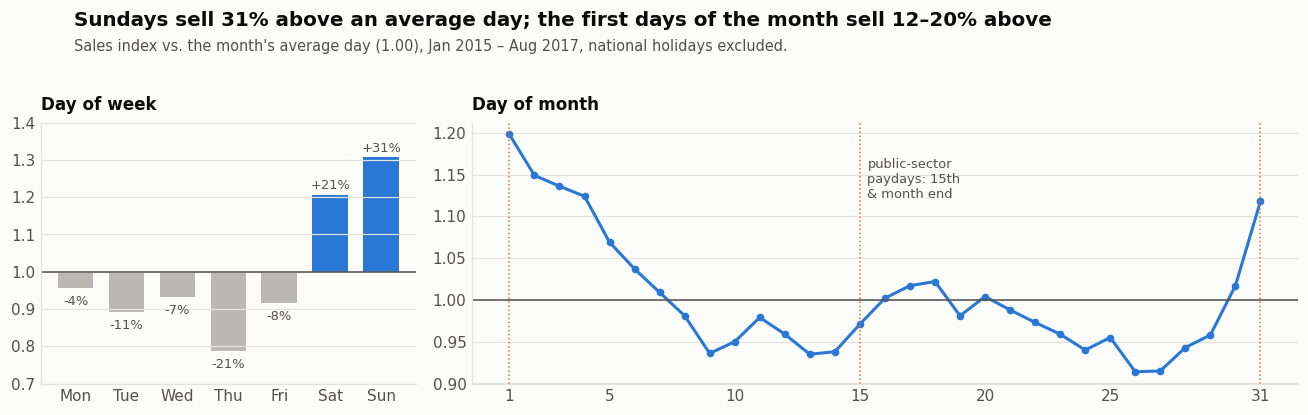

In [4]:
cal = query(con, "02_calendar_profile.sql")
dow = cal[cal.dimension == "day_of_week"]
dom = cal[cal.dimension == "day_of_month"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
a1.bar(names, dow.sales_index - 1, bottom=1, color=[style.BLUE if v >= 1 else style.MUTED for v in dow.sales_index], width=0.7)
a1.axhline(1, color=style.TEXT_2, lw=1)
a1.set_ylim(0.7, 1.4)
for x, v in enumerate(dow.sales_index):
    a1.text(x, v + (0.015 if v >= 1 else -0.045), f"{v - 1:+.0%}", ha="center", fontsize=8.5, color=style.TEXT_2)
a1.set_title("Day of week", fontsize=11, pad=8)

a2.plot(dom.key, dom.sales_index, color=style.BLUE, lw=2, marker="o", ms=4)
a2.axhline(1, color=style.TEXT_2, lw=1)
for d in (1, 15, 31):
    a2.axvline(d, color=style.ORANGE, lw=1, ls=":")
a2.text(15.3, 1.17, "public-sector\npaydays: 15th\n& month end", color=style.TEXT_2, fontsize=8.5, va="top")
a2.set_xticks([1, 5, 10, 15, 20, 25, 31])
a2.set_title("Day of month", fontsize=11, pad=8)
fig.suptitle("Sundays sell 31% above an average day; the first days of the month sell 12–20% above", x=0.06, ha="left", fontweight="bold", fontsize=13)
fig.text(0.06, 0.885, "Sales index vs. the month's average day (1.00), Jan 2015 – Aug 2017, national holidays excluded.", color=style.TEXT_2, fontsize=9.5)
fig.tight_layout(rect=(0, 0, 1, 0.9))
style.save(fig, "03_calendar")
plt.show()

**Decision:** add day-of-week, day-of-month, *days to month end* and a payday flag as features.

## 4. Product families: concentration and intermittency

In [5]:
fam = query(con, "03_family_mix.sql")
fam["cum_share_pct"] = fam.sales_share_pct.cumsum()
fam.head(12)

,family,sales_share_pct,growth_2016_pct,promo_day_share_pct,zero_sales_day_pct,cum_share_pct
0,GROCERY I,31.99,12.9,96.4,8.1,31.99
1,BEVERAGES,20.21,27.5,94.8,8.1,52.20
2,PRODUCE,11.43,72.9,74.8,28.4,63.63
3,CLEANING,9.08,1.1,92.6,8.1,72.71
4,DAIRY,6.01,14.4,87.8,8.1,78.72
5,BREAD/BAKERY,3.92,4.4,82.5,8.1,82.64
6,POULTRY,2.97,-1.1,31.1,8.1,85.61
7,MEATS,2.90,4.8,36.0,8.1,88.51
8,PERSONAL CARE,2.29,6.4,89.4,8.1,90.80
9,DELI,2.25,-2.8,82.0,8.1,93.05


In [6]:
top5 = fam.head(5).sales_share_pct.sum()
intermittent = fam[fam.zero_sales_day_pct > 40].family.tolist()
print(f"Top 5 families = {top5:.0f}% of units. Families with >40% zero-sales days: {len(intermittent)} -> {intermittent}")

Top 5 families = 79% of units. Families with >40% zero-sales days: 12 -> ['HOME CARE', 'CELEBRATION', 'LADIESWEAR', 'LAWN AND GARDEN', 'PLAYERS AND ELECTRONICS', 'SCHOOL AND OFFICE SUPPLIES', 'PET SUPPLIES', 'MAGAZINES', 'HARDWARE', 'BOOKS', 'BABY CARE', 'HOME APPLIANCES']


**Decision:** the metric must weight errors by volume (WAPE, alongside the competition's RMSLE), and series
with no sales in the last 56 days are forecast as zero.

## 5. Promotions

Promo days are compared with non-promo days of the **same store, family and month** to limit confounding by store
size and season ([`04_promo_lift.sql`](../sql/04_promo_lift.sql)). This is observational, so it is an upper-bound
style estimate rather than a causal effect.

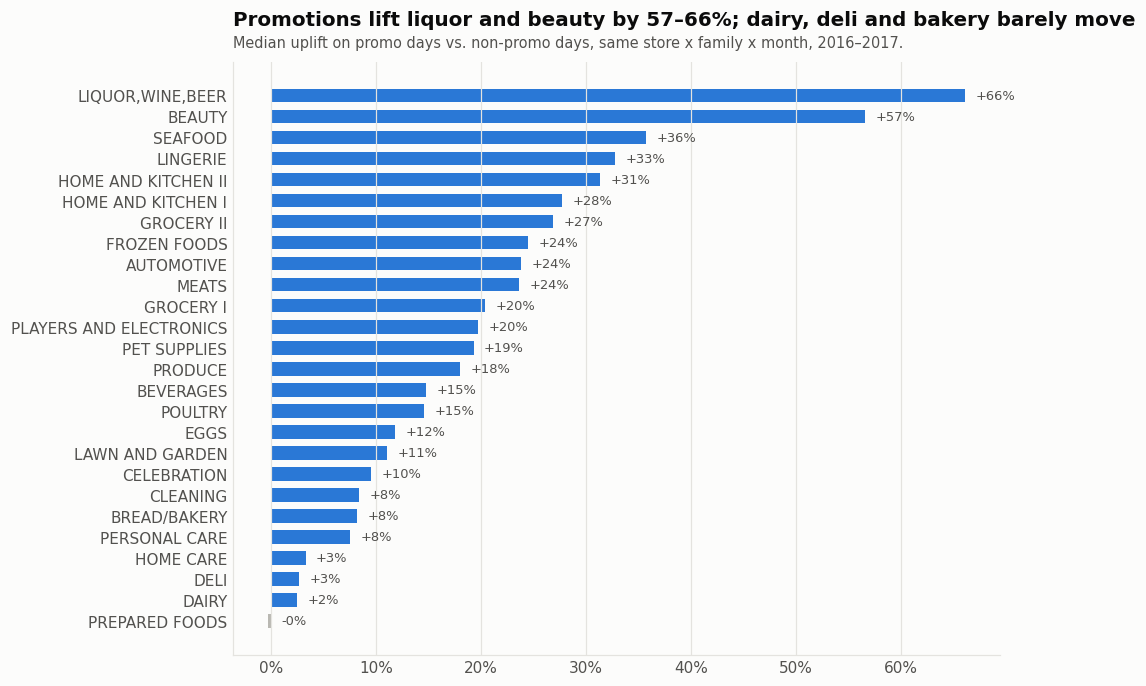

Excluded from chart: SCHOOL AND OFFICE SUPPLIES (+559%) — promotions coincide with back-to-school season.


In [7]:
promo = query(con, "04_promo_lift.sql")
show = promo[promo.family != "SCHOOL AND OFFICE SUPPLIES"].sort_values("median_uplift_pct")

fig, ax = plt.subplots(figsize=(9, 7))
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.barh(show.family, show.median_uplift_pct, color=[style.BLUE if v > 0 else style.MUTED for v in show.median_uplift_pct], height=0.65)
for y, v in enumerate(show.median_uplift_pct):
    ax.text(max(v, 0) + 1, y, f"{v:+.0f}%", va="center", fontsize=8.5, color=style.TEXT_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Promotions lift liquor and beauty by 57–66%; dairy, deli and bakery barely move")
style.subtitle(ax, "Median uplift on promo days vs. non-promo days, same store x family x month, 2016–2017.")
style.save(fig, "04_promo_uplift")
plt.show()
school = promo.loc[promo.family == "SCHOOL AND OFFICE SUPPLIES", "median_uplift_pct"].item()
print(f"Excluded from chart: SCHOOL AND OFFICE SUPPLIES ({school:+.0f}%) — promotions coincide with back-to-school season.")

**Decision:** use the number of items on promotion (known in advance) and how unusual it is versus the series'
recent promo level as features; the model learns the family-specific response.

## 6. Holidays

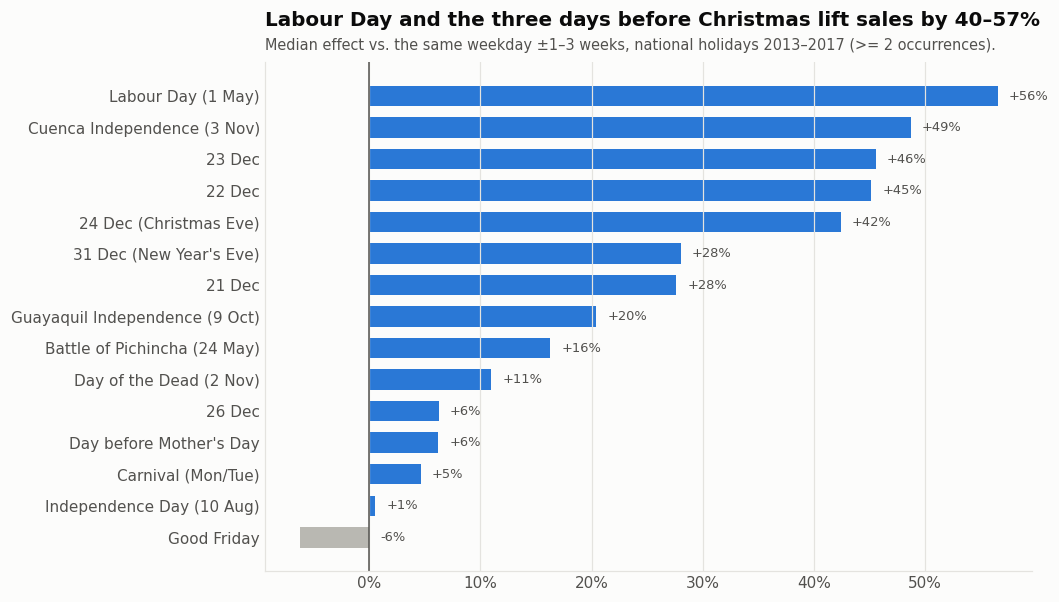

,occurrences,median_effect_pct
name,,
Labour Day (1 May),5,56.50
Cuenca Independence (3 Nov),4,48.70
23 Dec,4,45.55
22 Dec,4,45.15
24 Dec (Christmas Eve),4,42.40
31 Dec (New Year's Eve),4,28.00
21 Dec,4,27.60
Guayaquil Independence (9 Oct),4,20.40
Battle of Pichincha (24 May),5,16.30


In [8]:
hol = query(con, "05_holiday_effect.sql")
english = {
    "Dia del Trabajo": "Labour Day (1 May)", "Independencia de Cuenca": "Cuenca Independence (3 Nov)",
    "Navidad-4": "21 Dec", "Navidad-3": "22 Dec", "Navidad-2": "23 Dec", "Navidad-1": "24 Dec (Christmas Eve)",
    "Navidad+1": "26 Dec", "Primer dia del ano-1": "31 Dec (New Year's Eve)",
    "Independencia de Guayaquil": "Guayaquil Independence (9 Oct)", "Batalla de Pichincha": "Battle of Pichincha (24 May)",
    "Dia de Difuntos": "Day of the Dead (2 Nov)", "Dia de la Madre-1": "Day before Mother's Day",
    "Carnaval": "Carnival (Mon/Tue)", "Primer Grito de Independencia": "Independence Day (10 Aug)",
    "Viernes Santo": "Good Friday",
}
hol["name"] = hol.description.str.replace(r"^Traslado ", "", regex=True)
hol["name"] = hol.name.map(english).fillna(hol.name)
is_new_year = (pd.to_datetime(hol.date).dt.month == 1) & (pd.to_datetime(hol.date).dt.day == 1)   # stores closed
agg = (hol[~is_new_year]
          .groupby("name").agg(occurrences=("effect_pct", "size"), median_effect_pct=("effect_pct", "median"))
          .query("occurrences >= 2").sort_values("median_effect_pct"))

fig, ax = plt.subplots(figsize=(9, 6))
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.barh(agg.index, agg.median_effect_pct, color=[style.BLUE if v > 0 else style.MUTED for v in agg.median_effect_pct], height=0.65)
ax.axvline(0, color=style.TEXT_2, lw=1)
for y, v in enumerate(agg.median_effect_pct):
    ax.text(max(v, 0) + 1, y, f"{v:+.0f}%", va="center", fontsize=8.5, color=style.TEXT_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Labour Day and the three days before Christmas lift sales by 40–57%")
style.subtitle(ax, "Median effect vs. the same weekday ±1–3 weeks, national holidays 2013–2017 (>= 2 occurrences).")
style.save(fig, "05_holidays")
plt.show()
agg.sort_values("median_effect_pct", ascending=False)

**Decision:** national and local (city/state) holiday flags plus day-of-year so the model can learn the
pre-Christmas ramp. 25 December is a closed day and is excluded from training and scoring.

## 7. External signal tested and rejected: oil price

In [9]:
oil = query(con, "06_oil_vs_sales.sql")
oil = oil[oil.month >= "2015-06-01"].set_index("month")
level_corr = oil.oil_price.corr(oil.sales_per_open_store)
change_corr = oil.oil_price.pct_change().corr(oil.sales_per_open_store.pct_change())
print(f"Correlation of levels: {level_corr:+.2f} | correlation of month-on-month changes: {change_corr:+.2f}")

Correlation of levels: +0.19 | correlation of month-on-month changes: +0.07


Ecuador's economy depends on oil exports, so the oil price was a plausible demand driver. Over the training period
neither the levels nor the month-on-month changes are meaningfully correlated with sales per store, and the price is
not known for the forecast horizon anyway. **Decision:** not used.

## 8. Store formats

In [10]:
query(con, "07_store_types.sql")

,store_type,stores,avg_sales_per_day,avg_transactions_per_day,avg_ticket
0,A,8,31482.0,3172.0,9.92
1,D,18,14552.0,1574.0,9.25
2,B,8,13828.0,1628.0,8.49
3,E,4,12008.0,1182.0,10.16
4,C,15,7893.0,996.0,7.92


Type A stores sell twice as much per day as any other format, mostly through traffic rather than ticket size.
**Decision:** store number, type, cluster and city enter the model as categorical features.